In [1]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

train_df = pd.read_csv(
    PROJECT_ROOT / "data/processed/train_engineered.csv"
)

val_df = pd.read_csv(
    PROJECT_ROOT / "data/processed/validation_engineered.csv"
)

feature_columns = (
    PROJECT_ROOT / "docs/feature-columns.txt"
).read_text(encoding="utf-8-sig").splitlines()

X_train = train_df[feature_columns]
y_train = train_df["RUL"]

X_val = val_df[feature_columns]
y_val = val_df["RUL"]

assert set(train_df.engine_id).isdisjoint(set(val_df.engine_id))
assert len(feature_columns) == 123

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Data ready for training!")


Training: (16561, 123)
Validation: (4070, 123)
Data ready for training!


In [2]:

models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = np.maximum(model.predict(X_val), 0)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"{name}")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}\n")

results_df = pd.DataFrame(results)

display(results_df)

results_df.to_csv(
    PROJECT_ROOT / "ml/reports/baseline_results.csv",
    index=False
)


Dummy Regressor
MAE: 55.3633
RMSE: 65.7154

Ridge Regression
MAE: 23.6518
RMSE: 30.1053



,Model,MAE,RMSE
0,Dummy Regressor,55.363284,65.715445
1,Ridge Regression,23.651824,30.105298


In [3]:

# Step 14: Advanced ML Models

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd

advanced_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=350,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )
}

advanced_results = []

for name, model in advanced_models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(
        y_val, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val, predictions
        )
    )

    advanced_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"{name} Training Completed!")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")

advanced_results_df = pd.DataFrame(
    advanced_results
)

display(advanced_results_df)



Training Random Forest...
Random Forest Training Completed!
MAE: 23.1459
RMSE: 31.7680

Training XGBoost...
XGBoost Training Completed!
MAE: 23.6669
RMSE: 32.5083


,Model,MAE,RMSE
0,Random Forest,23.145924,31.767971
1,XGBoost,23.666893,32.508281


In [4]:

# Compare baseline and advanced models

all_results_df = pd.concat(
    [results_df, advanced_results_df],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("===== COMPLETE MODEL COMPARISON =====")

display(all_results_df.round(4))

# Save results
all_results_df.to_csv(
    PROJECT_ROOT / "ml/reports/model_comparison.csv",
    index=False
)

print("\nResults saved successfully!")


===== COMPLETE MODEL COMPARISON =====


,Model,MAE,RMSE
0,Ridge Regression,23.6518,30.1053
1,Random Forest,23.1459,31.7680
2,XGBoost,23.6669,32.5083
3,Dummy Regressor,55.3633,65.7154



Results saved successfully!


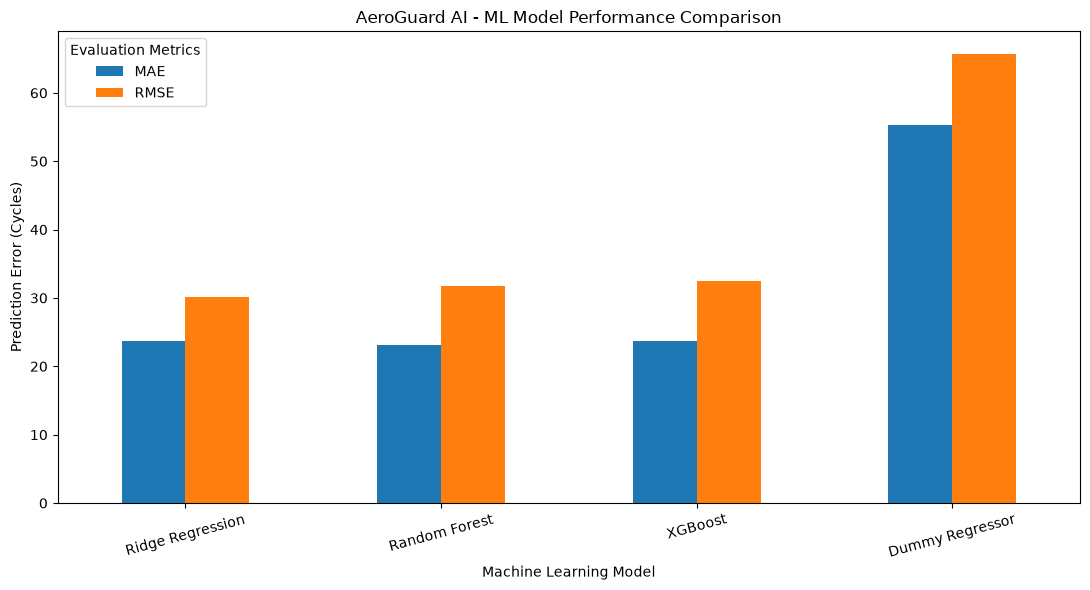

In [5]:

import matplotlib.pyplot as plt

ax = all_results_df.set_index("Model")[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(11, 6),
    rot=15
)

plt.title(
    "AeroGuard AI - ML Model Performance Comparison"
)

plt.ylabel("Prediction Error (Cycles)")
plt.xlabel("Machine Learning Model")
plt.legend(title="Evaluation Metrics")

plt.tight_layout()

figures_dir = (
    PROJECT_ROOT / "ml" / "reports" / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    figures_dir / "model_comparison.png",
    dpi=200
)

plt.show()


In [6]:

# Step 15.1 — Partial Engine Validation

import numpy as np
import pandas as pd

snapshots = []

# Evaluate at 50%, 70%, and 90% of engine lifetime
fractions = [0.50, 0.70, 0.90]

for engine_id, engine_df in val_df.groupby("engine_id"):

    engine_df = engine_df.sort_values("cycle")

    max_cycle = int(engine_df["cycle"].max())

    for fraction in fractions:

        cutoff = int(max_cycle * fraction)

        # Never use the failure cycle
        cutoff = max(
            1,
            min(cutoff, max_cycle - 1)
        )

        # Only observations up to this cycle
        history = engine_df[
            engine_df["cycle"] <= cutoff
        ]

        snapshot = history.iloc[-1].copy()

        snapshot["snapshot_fraction"] = fraction

        snapshots.append(snapshot)

snapshot_df = pd.DataFrame(
    snapshots
).reset_index(drop=True)

X_snapshot = snapshot_df[feature_columns]
y_snapshot = snapshot_df["RUL"]

assert len(snapshot_df) == 60
assert snapshot_df["engine_id"].nunique() == 20
assert (snapshot_df["RUL"] > 0).all()
assert not X_snapshot.isna().any().any()

print("===== PARTIAL ENGINE VALIDATION =====")
print("Validation engines:", snapshot_df.engine_id.nunique())
print("Total snapshots:", len(snapshot_df))
print("Feature shape:", X_snapshot.shape)
print("RUL range:", y_snapshot.min(), "to", y_snapshot.max())

display(
    snapshot_df[
        ["engine_id", "cycle",
         "snapshot_fraction", "RUL"]
    ].head(10)
)


===== PARTIAL ENGINE VALIDATION =====
Validation engines: 20
Total snapshots: 60
Feature shape: (60, 123)
RUL range: 14.0 to 135.0


,engine_id,cycle,snapshot_fraction,RUL
0,1.0,96.0,0.5,96.0
1,1.0,134.0,0.7,58.0
2,1.0,172.0,0.9,20.0
3,5.0,134.0,0.5,135.0
4,5.0,188.0,0.7,81.0
5,5.0,242.0,0.9,27.0
6,11.0,120.0,0.5,120.0
7,11.0,168.0,0.7,72.0
8,11.0,216.0,0.9,24.0
9,13.0,81.0,0.5,82.0


In [7]:

# Step 15.2 — Snapshot Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

all_models = {
    **models,
    **advanced_models
}

snapshot_results = []
prediction_details = snapshot_df[
    ["engine_id", "cycle", "snapshot_fraction", "RUL"]
].copy()

for name, model in all_models.items():

    predictions = model.predict(X_snapshot)

    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(
        y_snapshot, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_snapshot, predictions
        )
    )

    snapshot_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    prediction_details[name] = predictions

    print(f"\n{name}")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")

snapshot_results_df = pd.DataFrame(
    snapshot_results
).sort_values("RMSE")

print("\n===== SNAPSHOT MODEL COMPARISON =====")

display(snapshot_results_df.round(4))

# Save evidence
reports_dir = PROJECT_ROOT / "ml" / "reports"

snapshot_results_df.to_csv(
    reports_dir / "snapshot_model_comparison.csv",
    index=False
)

prediction_details.to_csv(
    reports_dir / "snapshot_prediction_details.csv",
    index=False
)

print("\nSnapshot evaluation results saved!")



Dummy Regressor
MAE: 51.3604
RMSE: 59.2117

Ridge Regression
MAE: 23.1817
RMSE: 28.5666

Random Forest
MAE: 14.6206
RMSE: 22.1716

XGBoost
MAE: 15.3077
RMSE: 22.4670

===== SNAPSHOT MODEL COMPARISON =====


,Model,MAE,RMSE
2,Random Forest,14.6206,22.1716
3,XGBoost,15.3077,22.4670
1,Ridge Regression,23.1817,28.5666
0,Dummy Regressor,51.3604,59.2117



Snapshot evaluation results saved!


In [ ]:

# Step 15.3 — Performance by lifecycle stage

from typing import cast

stage_results = []

for model_name in all_models:

    for fraction, group in prediction_details.groupby(
        "snapshot_fraction"
    ):

        # Tell Pylance the grouping key is a float
        fraction_value = cast(float, fraction)

        # Convert fraction into lifecycle percentage
        lifecycle_stage = f"{int(round(fraction_value * 100))}%"

        # Calculate Mean Absolute Error
        mae = mean_absolute_error(
            group["RUL"],
            group[model_name]
        )

        # Calculate Root Mean Squared Error
        rmse = np.sqrt(
            mean_squared_error(
                group["RUL"],
                group[model_name]
            )
        )

        # Save results
        stage_results.append({
            "Model": model_name,
            "Lifecycle Stage": lifecycle_stage,
            "MAE": mae,
            "RMSE": rmse
        })

# Create results DataFrame
stage_df = pd.DataFrame(stage_results)

# Display lifecycle performance
print("===== LIFECYCLE STAGE PERFORMANCE =====")
display(stage_df.round(4))

# Save evaluation results
stage_df.to_csv(
    reports_dir / "lifecycle_stage_results.csv",
    index=False
)

print("Lifecycle evaluation results saved successfully!")


,Model,Lifecycle Stage,MAE,RMSE
0,Dummy Regressor,50%,19.6256,21.7868
1,Dummy Regressor,70%,46.8278,48.4561
2,Dummy Regressor,90%,87.6278,87.7236
3,Ridge Regression,50%,28.2728,34.8962
4,Ridge Regression,70%,24.3832,29.0953
5,Ridge Regression,90%,16.8892,19.5926
6,Random Forest,50%,23.1413,29.4253
7,Random Forest,70%,16.6967,24.1135
8,Random Forest,90%,4.0238,5.2368
9,XGBoost,50%,24.3519,30.0440
